Customer snapshot date: 2026-06-30
K-selection results (near_elbow marks the elbow neighborhood):
 K   inertia  silhouette  near_elbow
 2 90653.445       0.196       False
 3 80618.205       0.145       False
 4 72805.419       0.147       False
 5 66425.048       0.159        True
 6 61780.534       0.169        True
 7 59420.342       0.169        True
 8 57549.234       0.166       False
 9 55493.957       0.136       False
10 53780.887       0.134       False
Elbow estimate: K=6; selected K=6 by the best nearby silhouette score.


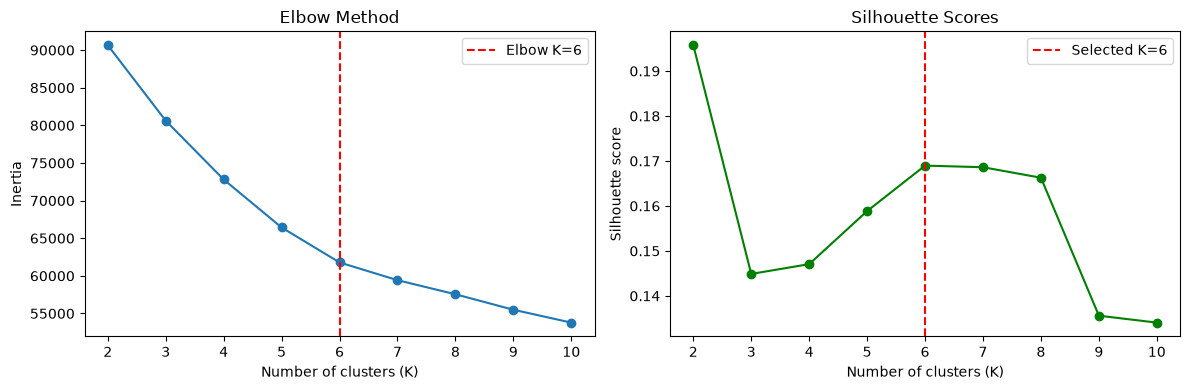

In [2]:
# Model 2: group customers with K-Means using engagement, billing, tenure, and satisfaction.
# Import Path so this notebook can locate project files on different operating systems.  # Explain paths.
from pathlib import Path
# Import plotting tools to show the elbow curve and silhouette scores.  # Explain charts.
import matplotlib.pyplot as plt
# Import NumPy for calculations used to estimate the elbow.  # Explain numeric tools.
import numpy as np
# Import pandas to load, join, and summarize customer tables.  # Explain data tools.
import pandas as pd
# Import K-Means and silhouette scoring for clustering and K selection.  # Explain clustering tools.
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
# Import median imputation and scaling to prepare numeric clustering features.  # Explain preprocessing.
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Fix randomness so the K-Means initialization and silhouette sample are repeatable.  # Explain seed.
RANDOM_STATE = 42
# Use the current folder as the starting point for finding the project.  # Explain folder.
PROJECT_DIR = Path.cwd()
# Move one folder up when this notebook is opened from the notebooks folder.  # Explain fallback.
if not (PROJECT_DIR / "data" / "processed").exists():
    PROJECT_DIR = PROJECT_DIR.parent
# Store the folder containing the project's curated CSV files.  # Explain data path.
DATA_DIR = PROJECT_DIR / "data" / "processed"
# Save final assignments under a new name so an existing locked CSV is left untouched.  # Explain export path.
OUTPUT_FILE = DATA_DIR / "output_customer_segments_final.csv"

# Load customer registration dates to calculate each customer's tenure.  # Explain customer table.
customers = pd.read_csv(DATA_DIR / "customers.csv", parse_dates=["registration_date"])
# Load precomputed viewing summaries as measures of engagement.  # Explain engagement table.
viewing = pd.read_csv(DATA_DIR / "customer_viewing_features.csv")
# Load subscription records and parse their start dates.  # Explain subscription table.
subscriptions = pd.read_csv(DATA_DIR / "subscriptions.csv", parse_dates=["subscription_start_date"])
# Load payment records and parse their dates.  # Explain payment table.
payments = pd.read_csv(DATA_DIR / "payments.csv", parse_dates=["payment_date"])
# Load feedback records and parse the dates customers submitted them.  # Explain feedback table.
feedback = pd.read_csv(DATA_DIR / "customer_feedback.csv", parse_dates=["feedback_date"])
# Choose one common snapshot at the latest date found in any source.  # Explain snapshot date.
AS_OF_DATE = max(customers["registration_date"].max(), subscriptions["subscription_start_date"].max(), payments["payment_date"].max(), feedback["feedback_date"].max())
# Display the date that defines this segmentation snapshot.  # Explain date output.
print(f"Customer snapshot date: {AS_OF_DATE.date()}")

# Start one row per customer with the registration date.  # Explain customer base.
customer_data = customers[["customer_id", "registration_date"]].copy()
# Calculate tenure as the number of days from registration to the snapshot.  # Explain tenure feature.
customer_data["tenure_days"] = (AS_OF_DATE - customer_data["registration_date"]).dt.days
# Keep viewing frequency, minutes watched, completion, and device diversity as engagement features.  # Explain engagement features.
engagement = viewing[["customer_id", "session_count", "total_watch_duration_minutes", "mean_completion_percentage", "distinct_device_count"]].rename(columns={"session_count": "viewing_sessions", "total_watch_duration_minutes": "watch_minutes", "distinct_device_count": "distinct_devices"})
# Exclude subscriptions that began after the selected snapshot date.  # Explain subscription cutoff.
subscriptions = subscriptions.loc[subscriptions["subscription_start_date"] <= AS_OF_DATE].copy()
# Sort subscriptions so the latest plan is last for each customer.  # Explain plan ordering.
subscriptions = subscriptions.sort_values(["customer_id", "subscription_start_date", "subscription_id"])
# Summarize monthly plan price and subscription count for billing context.  # Explain subscription features.
plan_features = subscriptions.groupby("customer_id").agg(monthly_price=("monthly_price", "last"), subscription_count=("subscription_id", "nunique")).reset_index()
# Exclude payments made after the common snapshot date.  # Explain payment cutoff.
payments = payments.loc[payments["payment_date"] <= AS_OF_DATE].copy()
# Mark failed payments as 1 so their average becomes each customer's failure share.  # Explain failure flag.
payments["failed_payment"] = payments["payment_status"].str.casefold().eq("failed").astype(int)
# Summarize payment volume, typical payment amount, and failed-payment rate.  # Explain billing behavior.
payment_features = payments.groupby("customer_id").agg(payment_count=("payment_id", "nunique"), mean_payment_amount=("amount", "mean"), failed_payment_rate=("failed_payment", "mean")).reset_index()
# Exclude feedback submitted after the snapshot date.  # Explain feedback cutoff.
feedback = feedback.loc[feedback["feedback_date"] <= AS_OF_DATE].copy()
# Encode positive sentiment as 1 and other sentiment as 0 for averaging.  # Explain sentiment feature.
feedback["positive_feedback"] = feedback["sentiment_label"].str.casefold().eq("positive").astype(int)
# Summarize average rating, positive-feedback share, and feedback count.  # Explain satisfaction features.
satisfaction = feedback.groupby("customer_id").agg(mean_feedback_rating=("rating", "mean"), positive_feedback_share=("positive_feedback", "mean"), feedback_count=("feedback_id", "nunique")).reset_index()
# Join each group of customer-level features onto the customer table.  # Explain feature joining.
for features in (engagement, plan_features, payment_features, satisfaction):
    customer_data = customer_data.merge(features, on="customer_id", how="left", validate="one_to_one")
# Fill missing counts with zero because no related records means no recorded events.  # Explain empty history.
count_columns = ["viewing_sessions", "distinct_devices", "subscription_count", "payment_count", "feedback_count"]
customer_data[count_columns] = customer_data[count_columns].fillna(0)
# Treat missing total viewing time as zero when a customer has no viewing record.  # Explain viewing default.
customer_data["watch_minutes"] = customer_data["watch_minutes"].fillna(0)

# Choose the numeric measurements representing engagement, billing, tenure, and satisfaction.  # Explain features.
feature_columns = ["viewing_sessions", "watch_minutes", "mean_completion_percentage", "distinct_devices", "monthly_price", "subscription_count", "payment_count", "mean_payment_amount", "failed_payment_rate", "tenure_days", "mean_feedback_rating", "positive_feedback_share", "feedback_count"]
# Make a feature matrix without customer IDs or dates.  # Explain model input.
X = customer_data[feature_columns].copy()
# Require enough rows to compare at least two different cluster counts.  # Explain minimum data.
if len(X) < 3:
    raise ValueError("At least three customers are required for K-Means selection.")
# Fill missing feature values with their column medians.  # Explain imputation.
imputed_features = SimpleImputer(strategy="median").fit_transform(X)
# Standardize features so large-unit variables do not dominate distance calculations.  # Explain scaling.
X_scaled = StandardScaler().fit_transform(imputed_features)

# Try K values from 2 to 10, stopping before K reaches the customer count.  # Explain K search.
k_values = list(range(2, min(10, len(X) - 1) + 1))
# Prepare storage for each fitted model and its two selection scores.  # Explain score storage.
models, inertias, silhouettes = {}, [], []
# Fit one K-Means model for every candidate cluster count.  # Explain model comparison.
for k in k_values:
    # Use 20 starting configurations to reduce sensitivity to initial cluster positions.  # Explain initialization.
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    # Assign every customer to a cluster for this candidate K.  # Explain model fitting.
    labels = model.fit_predict(X_scaled)
    # Keep the fitted model so the selected K can be reused.  # Explain stored model.
    models[k] = model
    # Record inertia, the within-cluster squared distance used by the elbow method.  # Explain elbow score.
    inertias.append(model.inertia_)
    # Estimate silhouette on at most 500 customers to keep this score practical for a large dataset.  # Explain sample.
    silhouettes.append(silhouette_score(X_scaled, labels, sample_size=min(500, len(X_scaled)), random_state=RANDOM_STATE))
# Normalize both elbow axes so their different units do not skew the elbow calculation.  # Explain normalization.
k_scaled = (np.array(k_values) - min(k_values)) / max(max(k_values) - min(k_values), 1)
inertia_values = np.array(inertias)
inertia_scaled = (inertia_values - inertia_values.min()) / max(np.ptp(inertia_values), 1e-12)
# Make points from the normalized K and inertia values.  # Explain elbow coordinates.
elbow_points = np.column_stack((k_scaled, inertia_scaled))
# Use the first and last points as the straight-line reference for the elbow.  # Explain reference line.
line_start, line_end = elbow_points[0], elbow_points[-1]
line_length = np.linalg.norm(line_end - line_start)
# Select the point furthest from the reference line as the estimated elbow.  # Explain elbow estimate.
if line_length == 0:
    elbow_index = 0
else:
    elbow_distances = np.abs((line_end[0] - line_start[0]) * (line_start[1] - elbow_points[:, 1]) - (line_start[0] - elbow_points[:, 0]) * (line_end[1] - line_start[1])) / line_length
    elbow_index = int(np.argmax(elbow_distances))
elbow_k = k_values[elbow_index]
# Keep the elbow and its immediate neighbors as candidates for the final K.  # Explain elbow neighborhood.
elbow_candidates = [k for k in k_values if abs(k - elbow_k) <= 1]
# Choose the candidate in that neighborhood with the highest silhouette score.  # Explain K decision.
selected_k = max(elbow_candidates, key=lambda k: silhouettes[k_values.index(k)])
# Display every tested K, its scores, and whether it is near the elbow.  # Explain results table.
selection = pd.DataFrame({"K": k_values, "inertia": inertias, "silhouette": silhouettes})
selection["near_elbow"] = selection["K"].isin(elbow_candidates)
print("K-selection results (near_elbow marks the elbow neighborhood):")
print(selection.to_string(index=False, float_format=lambda value: f"{value:.3f}"))
print(f"Elbow estimate: K={elbow_k}; selected K={selected_k} by the best nearby silhouette score.")
# Plot the full-data elbow inertia and sampled silhouette scores side by side.  # Explain charts.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_values, inertias, marker="o")
axes[0].axvline(elbow_k, color="red", linestyle="--", label=f"Elbow K={elbow_k}")
axes[0].set(title="Elbow Method", xlabel="Number of clusters (K)", ylabel="Inertia")
axes[0].legend()
axes[1].plot(k_values, silhouettes, marker="o", color="green")
axes[1].axvline(selected_k, color="red", linestyle="--", label=f"Selected K={selected_k}")
axes[1].set(title="Silhouette Scores", xlabel="Number of clusters (K)", ylabel="Silhouette score")
axes[1].legend()
plt.tight_layout()
plt.show()
# Add the selected model's cluster number to every customer row.  # Explain final cluster labels.
customer_data["cluster"] = models[selected_k].labels_
# Calculate the average original-scale feature values for each cluster.  # Explain cluster profiles.
profiles = customer_data.groupby("cluster")[feature_columns].mean()
# Add the number and share of customers represented by each group.  # Explain cluster sizes.
profiles.insert(0, "customer_count", customer_data.groupby("cluster").size())
profiles.insert(1, "customer_share", profiles["customer_count"] / len(customer_data))
# Calculate whole-customer medians as reference points for naming the clusters.  # Explain naming benchmarks.
reference = customer_data[feature_columns].median()

In [4]:
# Refine broad labels so each segment name reflects its clearest measured pattern.  # Explain why this step exists.
refined_names, refined_descriptions, used_names = {}, {}, set()
# Apply the same ordered business rules to each calculated cluster profile.  # Explain the refinement loop.
for cluster_id, profile in profiles.iterrows():
    # Keep low-engagement and low-satisfaction customers visible for possible retention follow-up.  # Explain at-risk segment.
    if profile["viewing_sessions"] < reference["viewing_sessions"] and profile["mean_feedback_rating"] < reference["mean_feedback_rating"]:
        name, note = "At-Risk Low-Engagement", "Watches less often and reports lower-than-typical satisfaction; this is a follow-up signal, not a churn prediction."
    # Keep the most engaged, established, satisfied group distinct.  # Explain loyal segment.
    elif profile["viewing_sessions"] >= reference["viewing_sessions"] and profile["tenure_days"] >= reference["tenure_days"] and profile["mean_feedback_rating"] >= reference["mean_feedback_rating"]:
        name, note = "High-Value Loyal", "Combines frequent viewing, established tenure, and stronger satisfaction."
    # Distinguish newer customers before checking other behavior patterns.  # Explain newer customers.
    elif profile["tenure_days"] < reference["tenure_days"]:
        name, note = "Newer Subscribers", "Has shorter-than-typical tenure; do not assume price sensitivity from tenure alone."
    # Identify groups with more recorded subscriptions than the typical customer.  # Explain repeat plans.
    elif profile["subscription_count"] > reference["subscription_count"]:
        name, note = "Multi-Plan Customers", "Has more recorded subscriptions than typical, which may reflect plan changes or renewals."
    # Identify frequent viewers with a below-median current monthly plan price.  # Explain value seekers.
    elif profile["viewing_sessions"] >= reference["viewing_sessions"] and profile["monthly_price"] < reference["monthly_price"]:
        name, note = "Engaged Value Seekers", "Views frequently while paying below the typical monthly plan price."
    # Separate highly active groups whose satisfaction remains below the customer median.  # Explain satisfaction opportunity.
    elif profile["viewing_sessions"] >= reference["viewing_sessions"] and profile["mean_feedback_rating"] < reference["mean_feedback_rating"]:
        name, note = "Engaged, Low-Satisfaction", "Views frequently but reports lower-than-typical satisfaction, suggesting a content or service opportunity."
    # Flag remaining groups whose failed-payment share is elevated.  # Explain payment follow-up.
    elif profile["failed_payment_rate"] > max(reference["failed_payment_rate"], 0.05):
        name, note = "Payment-Risk Customers", "Has an elevated failed-payment share and may benefit from billing support."
    # Use a neutral label when no more specific rule describes the customer group.  # Explain fallback.
    else:
        name, note = "Established Mainstream Members", "Has established tenure without one stronger defining behavior."
    # Keep names unique when different clusters match the same business rule.  # Explain duplicate names.
    if name in used_names:
        name = f"{name} (Cluster {cluster_id})"
    used_names.add(name)
    # Store the chosen name and measured details for later display and export.  # Explain label mapping.
    refined_names[cluster_id] = name
    refined_descriptions[cluster_id] = f"{note} Average tenure: {profile['tenure_days']:.0f} days; viewing sessions: {profile['viewing_sessions']:.1f}; plan price: ${profile['monthly_price']:.2f}/month; rating: {profile['mean_feedback_rating']:.2f}/5."
# Replace the broad profile labels with the refined, business-readable labels.  # Explain report update.
profiles["segment_name"] = pd.Series(refined_names)
profiles["description"] = pd.Series(refined_descriptions)
# Update the customer-level labels using the refined mapping.  # Explain customer update.
customer_data["segment_name"] = customer_data["cluster"].map(refined_names)
customer_data["description"] = customer_data["cluster"].map(refined_descriptions)
# Show the final segment names and descriptions after refinement.  # Explain final report.
print("Final business-readable segment descriptions:")
print(profiles[["segment_name", "customer_count", "customer_share", "description"]].to_string())
# Replace the earlier export with the corrected final customer assignments.  # Explain final export.
customer_data[["customer_id", "cluster", "segment_name", "description"]].to_csv(OUTPUT_FILE, index=False)
# Confirm the final export path and number of customer rows.  # Explain completion.
print(f"Updated {len(customer_data):,} customer assignments at: {OUTPUT_FILE}")

Final business-readable segment descriptions:
                      segment_name  customer_count  customer_share                                                                                                                                                                                                      description
cluster                                                                                                                                                                                                                                                                            
0           At-Risk Low-Engagement            1171        0.146375  Watches less often and reports lower-than-typical satisfaction; this is a follow-up signal, not a churn prediction. Average tenure: 1427 days; viewing sessions: 3.2; plan price: $14.74/month; rating: 2.56/5.
1        Engaged, Low-Satisfaction            2203        0.275375           Views frequently but reports lower-than-typical s

# Customer Segmentation

This workflow builds customer-level engagement, billing, tenure, and satisfaction features; selects K with the elbow method and silhouette scores; then names and exports the customer groups.